# Probability and Loss Functions

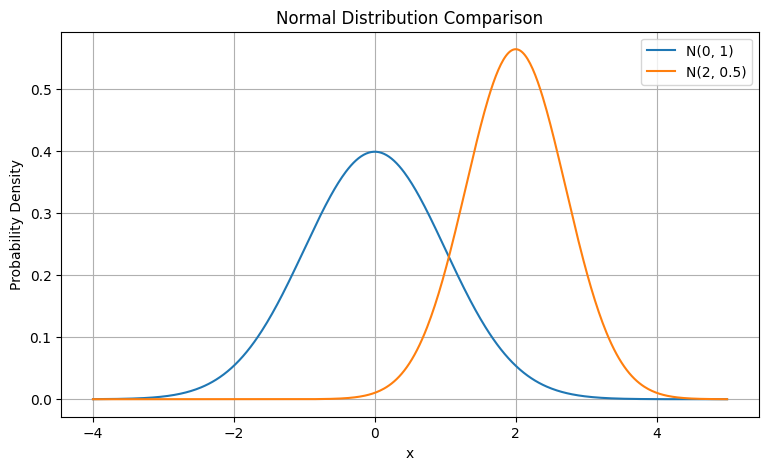

Normal distributions: PASS


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)

def normal_pdf(x, mu, variance):
    """Calculate the normal probability density function."""
    return (
        1 / np.sqrt(2 * np.pi * variance)
        * np.exp(-((x - mu) ** 2) / (2 * variance))
    )

x = np.linspace(-4, 5, 500)

pdf1 = normal_pdf(x, 0, 1)
pdf2 = normal_pdf(x, 2, 0.5)

plt.figure(figsize=(9, 5))

plt.plot(x, pdf1, label="N(0, 1)")
plt.plot(x, pdf2, label="N(2, 0.5)")

plt.title("Normal Distribution Comparison")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(True)

output_dir = Path("../outputs")
output_dir.mkdir(exist_ok=True)

plt.savefig(output_dir / "normal_distributions.png", dpi=150)
plt.show()

print("Normal distributions: PASS")


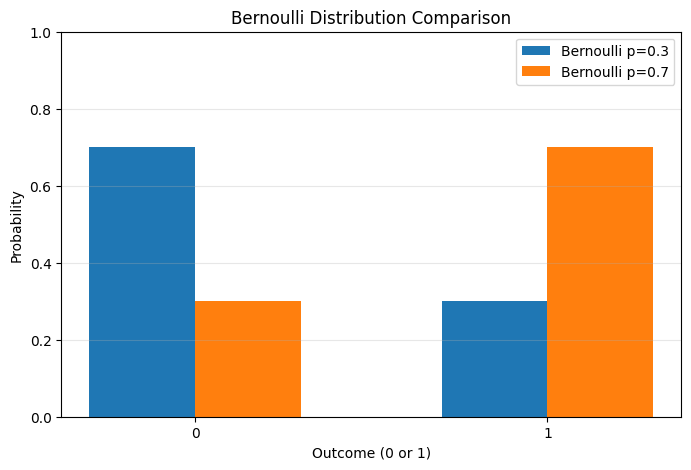

B(0.3): [0.7 0.3]
B(0.7): [0.3 0.7]
Bernoulli Validation: PASS


In [2]:

# Bernoulli PMF comparison

def bernoulli_pmf(x, p):
    """Calculate Bernoulli probability mass function."""
    return (p ** x) * ((1 - p) ** (1 - x))


values = np.array([0, 1])

pmf_03 = bernoulli_pmf(values, 0.3)
pmf_07 = bernoulli_pmf(values, 0.7)

fig, ax = plt.subplots(figsize=(8, 5))

width = 0.3

ax.bar(
    values - width / 2,
    pmf_03,
    width,
    label="Bernoulli p=0.3"
)

ax.bar(
    values + width / 2,
    pmf_07,
    width,
    label="Bernoulli p=0.7"
)

ax.set_xticks(values)
ax.set_xlabel("Outcome (0 or 1)")
ax.set_ylabel("Probability")
ax.set_title("Bernoulli Distribution Comparison")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

fig.savefig(
    output_dir / "bernoulli_distributions.png",
    dpi=150
)

plt.show()

print("B(0.3):", pmf_03)
print("B(0.7):", pmf_07)

assert np.isclose(np.sum(pmf_03), 1.0)
assert np.isclose(np.sum(pmf_07), 1.0)

print("Bernoulli Validation: PASS")


In [3]:

# Softmax implementation and validation

def softmax(z):
    """Calculate numerically stable softmax probabilities."""
    z = np.asarray(z, dtype=float)

    shifted = z - np.max(z)
    exp_values = np.exp(shifted)

    return exp_values / np.sum(exp_values)


# Example: scores for three classes
scores = np.array([2.0, 1.0, 0.1])

probabilities = softmax(scores)

total = np.sum(probabilities)
error = abs(total - 1.0)

print("Softmax Validation")
print("Input scores:", scores)
print("Probabilities:", probabilities)
print(f"Probability sum: {total:.10f}")
print(f"Error: {error:.10f}")

assert error <= 1e-6
print("Validation: PASS")


Softmax Validation
Input scores: [2.  1.  0.1]
Probabilities: [0.65900114 0.24243297 0.09856589]
Probability sum: 1.0000000000
Error: 0.0000000000
Validation: PASS



## MSE and Maximum Likelihood Estimation (MLE)

### 1. Gaussian Assumption

Assume the observed target follows:

$$
y_i=f_\theta(x_i)+\epsilon_i
$$

where the errors are independent and:

$$
\epsilon_i\sim \mathcal{N}(0,\sigma^2)
$$

Therefore:

$$
p(y_i|x_i,\theta)=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(y_i-f_\theta(x_i))^2}{2\sigma^2}
\right)
$$

### 2. Maximum Likelihood Estimation

For independent observations, the likelihood is:

$$
\mathcal{L}(\theta)
=\prod_{i=1}^{n}p(y_i|x_i,\theta)
$$

Taking the logarithm:

$$
\log\mathcal{L}(\theta)
=-\frac{n}{2}\log(2\pi\sigma^2)
-\frac{1}{2\sigma^2}
\sum_{i=1}^{n}(y_i-f_\theta(x_i))^2
$$

Assuming the variance is fixed, maximizing log-likelihood
is equivalent to minimizing squared errors:

$$
\arg\max_\theta\log\mathcal{L}(\theta)
=
\arg\min_\theta
\sum_{i=1}^{n}(y_i-f_\theta(x_i))^2
$$

Since dividing by n does not change the minimizer:

$$
\boxed{
\arg\max_\theta\mathcal{L}(\theta)
=
\arg\min_\theta MSE
}
$$

### Conclusion

Minimizing MSE is equivalent to MLE under an independent
Gaussian noise model with fixed variance.

---

## Cross-Entropy and Maximum Likelihood Estimation

### 1. Bernoulli Distribution

For binary classification, assume:

$$
y_i\sim Bernoulli(p_i)
$$

where:

$$
p_i=\hat y_i
$$

The probability of an observation is:

$$
p(y_i|x_i,\theta)
=
\hat y_i^{y_i}(1-\hat y_i)^{1-y_i}
$$

### 2. Log-Likelihood

For independent observations:

$$
\log\mathcal{L}(\theta)
=
\sum_{i=1}^{n}
\left[
y_i\log(\hat y_i)
+
(1-y_i)\log(1-\hat y_i)
\right]
$$

Taking the negative average:

$$
-\frac{1}{n}\log\mathcal{L}(\theta)
=
-\frac{1}{n}
\sum_{i=1}^{n}
\left[
y_i\log(\hat y_i)
+
(1-y_i)\log(1-\hat y_i)
\right]
$$

This is Binary Cross-Entropy (BCE).

Therefore:

$$
\boxed{
\arg\max_\theta\mathcal{L}(\theta)
=
\arg\min_\theta BCE
}
$$

### 3. Categorical Distribution

For multiclass classification, use Softmax probabilities:

$$
p_{ic}=
\frac{e^{z_{ic}}}
{\sum_j e^{z_{ij}}}
$$

With one-hot targets, categorical cross-entropy is:

$$
CE=
-\frac{1}{n}
\sum_{i=1}^{n}
\sum_{c=1}^{C}
y_{ic}\log(p_{ic})
$$

Minimizing categorical cross-entropy is equivalent
to maximizing the categorical log-likelihood
for independent observations.

### Conclusion

- MSE corresponds to Gaussian likelihood under fixed variance.
- BCE corresponds to Bernoulli likelihood.
- Categorical Cross-Entropy corresponds to categorical likelihood.
- Minimizing negative log-likelihood is equivalent to MLE.
